# 3 - Modèles

Comparaison et sélection de modèles pour la prédiction de `G3`.

* **Entrée** : `split/` (via `outils.load_split`) : seul le **train** est utilisé ici
* Tous les modèles sont comparés par **validation croisée à 5 plis sur le train**, avec le prétraitement (standardisation, one-hot) à l'intérieur du `Pipeline`, donc appris sur chaque pli d'entraînement seulement
* Métriques utilisées : RMSE et MAE (*Mean Absolute Error*) (en points sur 20) et le R².

C'est un problème de **régression** (`G3` est une note de 0 à 20). Un modèle linéaire adapté est donc la régression régularisée (Ridge, Lasso). C'est notamment pour cela que nous n'utiliserons pas la régression logstique qui sert à classer.

# Importation des librairies et des données

In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import outils as ot
from sklearn.base import clone
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold

In [2]:
X_train, X_test, y_train, y_test = ot.load_split() # test ne sera pas utilisé dans ce notebook
print(X_train.shape, y_train.shape)

(519, 32) (519,)


# Modèles

* **Baseline** : prédire toujours la moyenne du train. C'est le modèle (plutôt simple) à battre.
* **Ridge et Lasso** : régressions linéaires régularisées. Le Lasso met à zéro les coefficients des variables peu utiles, ce qui facilite l'interprétation.
* **Arbre de décision** : nous ferons attention à limiter la profondeur afin d'éviter le surapprentissage.
* **Forêt aléatoire** 
* **XGBoost** : arbres construits successivement, chacun corrigeant les erreurs des précédents. Peu de réglages sont faits ici, juste des valeurs prudentes (peu de profondeur, apprentissage lent).

In [3]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Lasso, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

models = {
    "Baseline (moyenne)": DummyRegressor(strategy="mean"),
    "Ridge": Ridge(alpha=10),
    "Lasso": Lasso(alpha=0.1, max_iter=10000),
    "Arbre": DecisionTreeRegressor(max_depth=4, random_state=ot.SEED),
    "Forêt aléatoire": RandomForestRegressor(n_estimators=200, min_samples_leaf=3,
                                              random_state=ot.SEED, n_jobs=-1),
    "XGBoost": XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=3,
                            subsample=0.8, colsample_bytree=0.8,
                            random_state=ot.SEED, verbosity=0),
}
list(models)

['Baseline (moyenne)', 'Ridge', 'Lasso', 'Arbre', 'Forêt aléatoire', 'XGBoost']

# Comparaison : scénarios × modèles

`ot.evaluate_cv` lance la validation croisée sur le train. Les scénarios (`ot.SCENARIOS`) ne changent que les variables fournies au modèle.

In [4]:
rows = []
for scenario, feats in ot.SCENARIOS.items():
    for nom, model in models.items():
        res = ot.evaluate_cv(model, X_train, y_train, feats)
        rows.append({"scenario": scenario, "modele": nom, **res})
resultats = pd.DataFrame(rows)
resultats.round(2)

,scenario,modele,rmse,rmse_std,mae,r2
0,A_G1_G2,Baseline (moyenne),3.23,0.17,2.40,-0.01
1,A_G1_G2,Ridge,1.35,0.24,0.86,0.82
2,A_G1_G2,Lasso,1.31,0.24,0.82,0.83
3,A_G1_G2,Arbre,1.50,0.14,0.88,0.78
4,A_G1_G2,Forêt aléatoire,1.35,0.18,0.86,0.82
5,A_G1_G2,XGBoost,1.39,0.23,0.90,0.81
6,B_G1,Baseline (moyenne),3.23,0.17,2.40,-0.01
7,B_G1,Ridge,1.92,0.31,1.27,0.64
8,B_G1,Lasso,1.87,0.32,1.22,0.66
9,B_G1,Arbre,1.97,0.19,1.32,0.63


Nous remarquons que garder `G1` et `G2` donne les meilleurs résultats : `rmse` et `mae` les plus faibles, ainsi que `r2` le plus élevé. Retirer `G2` fait augmenter la `rmse` ainsi que le `mae` et fait baisser le `r2`. Retirer `G1` et `G2` accentue encore plus cette tendance.

Concernant le scénario `A_G1_G2`, les modèles linéaires, `Ridge` et `Lasso` font aussi bien que les modèles complexes non linéaires, `Forêt aléatoire` et `XGBoost`. Cela peut montrer que la relation entre les notes intermédiaires et la note finale est quasi-linéaire. 

Sans les notes intermédiaires (`B_G1` et `C_sans_notes`), le modèle de `Forêt aléatoire` semble performer le mieux, avec un écart modeste cependant. En effet, le `rmse_std` (écart-type de la RMSE) mesure la variabilité des performances du modèle d'un pli à l'autre lors de la validation croisée et l'écart entre les meilleurs modèles de chaque scénario n'est pas plus grand que le `rmse_std`.

Tous les modèles performent mieux que la baseline, peu importe le scénario.

## RMSE par modèle et par scénario

Plus la RMSE est faible et plus le modèle est performant.

In [5]:
rmse = resultats.pivot(index="modele", columns="scenario", values="rmse").loc[list(models)]
rmse.round(2)

scenario,A_G1_G2,B_G1,C_sans_notes
modele,,,
Baseline (moyenne),3.23,3.23,3.23
Ridge,1.35,1.92,2.88
Lasso,1.31,1.87,2.86
Arbre,1.50,1.97,3.20
Forêt aléatoire,1.35,1.77,2.80
XGBoost,1.39,1.81,2.87


Nous remarquons que la `RSME` de la baseline est constante à $3.23$ peu importe le scénario. En effet, la baseline ne prend pas en compte `G1` ni `G2`.
* `A_G1_G2` : le meilleur modèle est `Lasso` avec une réduction de $3.23 - 1.31 = 1.92$ par rapport à la baseline
* `B_G1` : le meilleur modèle est la `Forêt aléatoire` avec une réduction de $3.23 - 1.77 = 1.46$ par rapport à la baseline
* `C_sans_notes` : le meilleur modèle reste la `Forêt aléatoire` avec une réduction de $3.23 - 2.80 = 0.43$ par rapport à la baseline

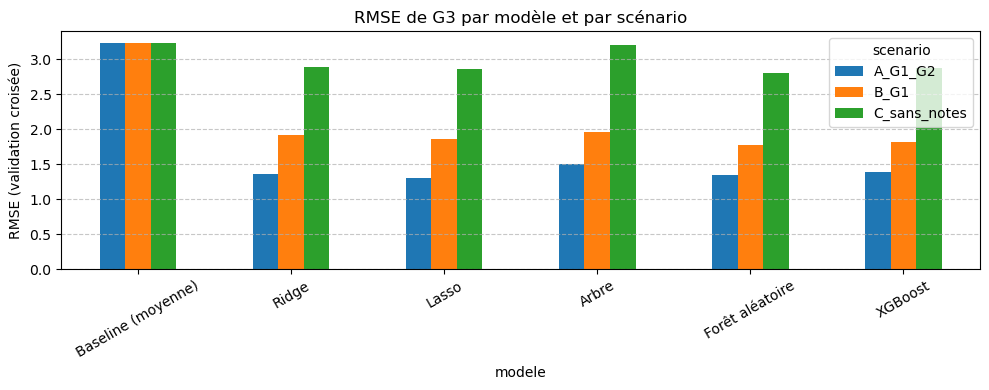

In [13]:
rmse.plot.bar(figsize=(10, 4), ylabel="RMSE (validation croisée)", rot=30)
plt.title("RMSE de G3 par modèle et par scénario")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## R² par modèle et par scénario
Plus R² est grand et meilleur est le modèle.

In [7]:
resultats.pivot(index="modele", columns="scenario", values="r2").loc[list(models)].round(2)

scenario,A_G1_G2,B_G1,C_sans_notes
modele,,,
Baseline (moyenne),-0.01,-0.01,-0.01
Ridge,0.82,0.64,0.20
Lasso,0.83,0.66,0.21
Arbre,0.78,0.63,0.01
Forêt aléatoire,0.82,0.70,0.24
XGBoost,0.81,0.68,0.21


Les notes antérieurs d'un.e élève sont de très bons prédicteurs de sa note finale. En l'absence de notes, bien que les variables socio-démographiques aient un impact réel, elles ne parviennent qu'à expliquer près de 20% de la note finale. Elles ne permettent pas de prédire précisément la note finale. 

# Effet des `G3 = 0` sur l'entraînement

Si nous filtrons `y_train > 0` avant la validation croisée, les zéros disparaîtraient aussi des élèves de validation et les scores ne seraient plus comparables. Ici, les **mêmes plis** sont utilisés dans les deux cas et la validation inclut toujours tous les élèves ; seule change la présence des zéros dans l'**entraînement**. Deux RMSE sont rapportés : sur tous les élèves de validation, et sur ceux dont `G3 > 0`.

In [8]:
def cv_zeros(model, X, y, features, drop_zeros, n_splits=5):
    kf = KFold(n_splits, shuffle=True, random_state=ot.SEED)   # mêmes plis que ot.evaluate_cv
    rmse_all, rmse_pos = [], []
    for tr, va in kf.split(X):
        X_tr, y_tr = X.iloc[tr], y.iloc[tr]
        if drop_zeros:
            keep = y_tr > 0
            X_tr, y_tr = X_tr[keep], y_tr[keep]
        pipe = ot.make_pipeline(clone(model), features).fit(X_tr, y_tr)
        pred = pipe.predict(X.iloc[va])
        y_va = y.iloc[va]
        rmse_all.append(mean_squared_error(y_va, pred) ** 0.5)
        pos = (y_va > 0).to_numpy()
        rmse_pos.append(mean_squared_error(y_va[pos], pred[pos]) ** 0.5)
    return {"rmse_tous": np.mean(rmse_all), "rmse_G3>0": np.mean(rmse_pos)}

# À adapter après lecture du tableau précédent
scenario_choisi = "C_sans_notes"
modele_choisi = "XGBoost"
feats = ot.SCENARIOS[scenario_choisi]

pd.DataFrame({
    "avec zéros à l'entraînement": cv_zeros(models[modele_choisi], X_train, y_train, feats, drop_zeros=False),
    "sans zéros à l'entraînement": cv_zeros(models[modele_choisi], X_train, y_train, feats, drop_zeros=True),
}).round(2)

,avec zéros à l'entraînement,sans zéros à l'entraînement
rmse_tous,2.87,2.84
rmse_G3>0,2.50,2.31


Retirer les zéros à la phase d'entraînement améliore le modèle (`rmse` qui diminue). Cette amélioration est plus marquée lorsque nous ne considérons pas les élèves qui ont eu 0 pour `G3`. Elle est cependant tout de même présente même lorsque nous prenons en compte tous les élèves.

# Réglage léger de XGBoost (optionnel)

Section à faire seulement s'il reste du temps. La grille est volontairement petite (12 combinaisons).

In [9]:
from sklearn.model_selection import GridSearchCV

pipe = ot.make_pipeline(XGBRegressor(subsample=0.8, colsample_bytree=0.8,
                                      random_state=ot.SEED, verbosity=0), feats)
grille = {"model__max_depth": [2, 3, 4],
          "model__n_estimators": [100, 300],
          "model__learning_rate": [0.03, 0.1]}
gs = GridSearchCV(pipe, grille, cv=KFold(5, shuffle=True, random_state=ot.SEED),
                  scoring="neg_root_mean_squared_error", n_jobs=-1)
gs.fit(X_train, y_train)
print("Meilleurs paramètres :", gs.best_params_)
print("RMSE CV :", round(-gs.best_score_, 2))

Meilleurs paramètres : {'model__learning_rate': 0.03, 'model__max_depth': 4, 'model__n_estimators': 100}
RMSE CV : 2.81


# Décisions pour la suite

*À compléter après lecture des résultats :*

* Scénario retenu pour l'évaluation finale : `...`
* Modèle retenu : `...` (hyperparamètres : `...`)
* Zéros : conservés ou retirés à l'entraînement, car `...`
* Dans `4-evaluation`, le modèle retenu sera entraîné sur **tout le train**, puis évalué **une seule fois** sur le test.